# 05 · Selección del modelo ganador y registro

1. Para cada modelo ajustado se elige su mejor configuración. Si la mejora del tuning **no supera la desviación entre pliegues**, se conserva la versión por defecto, que es más simple y tiene menos riesgo de haberse sobreajustado a la propia CV.
2. Ganador y segundo mejor se comparan con la media y la desviación de la CV, y pliegue a pliegue.
3. **Una sola** evaluación en la prueba (26-10 a 07-11) para los dos.
4. Métrica de negocio con un umbral de decisión elegido según el costo de cada error, usando predicciones **fuera de pliegue** (nunca la prueba).
5. Costo y explicabilidad.
6. Registro en el Model Registry con los alias `champion` y `challenger`.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="mlflow")   # avisos de esquema de MLflow
import os, logging
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT", "1")
logging.getLogger("mlflow").setLevel(logging.ERROR)   # avisos repetidos de serialización/entorno
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.inspection import permutation_importance

import src.pipeline as P
import src.tracking as T
from src.datos import cargar_obt
from src import estilo
estilo.aplicar()

T.configurar()
cliente = MlflowClient()
snap = cargar_obt()
div = P.dividir(P.agregar_features(snap.datos))
pliegues = P.pliegues_temporales(div.train)
X_tr, y_tr = div.train[P.ENTRADA], div.train[P.TARGET].to_numpy()
X_te, y_te = div.test[P.ENTRADA], div.test[P.TARGET].to_numpy()
staff_tr, staff_te = div.train.staff_present.to_numpy(), div.test.staff_present.to_numpy()

## 1. Configuración final de cada modelo ajustado

In [2]:
padres = mlflow.search_runs(filter_string="tags.fase = 'tuning' and tags.rol = 'padre'")
filas = []
for _, p in padres.iterrows():
    nombre = p["tags.mlflow.runName"].removeprefix("tuning_")
    mejora, desv_def = p["metrics.mejora_wape"], p["metrics.default_cv_wape_std"]
    usar_tuned = mejora > desv_def
    run_id = p["params.run_id_mejor_trial"] if usar_tuned else p["params.run_id_default"]
    m = mlflow.get_run(run_id).data.metrics
    filas.append({"modelo": nombre, "version": "tuning" if usar_tuned else "por defecto",
                  "mejora_tuning": mejora, "desv_default": desv_def, "cv_wape_mean": m["cv_wape_mean"],
                  "cv_wape_std": m["cv_wape_std"], "train_wape": m["train_wape"],
                  "cv_costo_negocio": m["cv_costo_negocio"], "fit_seconds": m["fit_seconds"], "run_id": run_id})
finalistas = pd.DataFrame(filas).set_index("modelo").sort_values("cv_wape_mean")
finalistas.round(4)

,version,mejora_tuning,desv_default,cv_wape_mean,cv_wape_std,train_wape,cv_costo_negocio,fit_seconds,run_id
modelo,,,,,,,,,
ridge,por defecto,0.0003,0.0354,0.3794,0.0354,0.3434,238.79,0.0027,6b1e7dac12dd4d31bdbab9716019b1d4
mlp,por defecto,0.0056,0.0428,0.3923,0.0428,0.3129,242.20,0.1427,19665330e867498f916197d6f496498f
random_forest,por defecto,0.0234,0.0281,0.4102,0.0281,0.1440,221.39,0.0523,9a26dec77bbd473f90e8bae2ed6caebe


## 2. Ganador frente al segundo mejor en la validación cruzada

In [3]:
ganador, segundo = finalistas.index[:2]
g, s = finalistas.loc[ganador], finalistas.loc[segundo]

def pliegues_de(run_id):
    h = cliente.get_metric_history(run_id, "cv_wape_pliegue")
    return np.array([m.value for m in sorted(h, key=lambda m: m.step)])

pl_g, pl_s = pliegues_de(g.run_id), pliegues_de(s.run_id)
dif = pl_s - pl_g
print(f"Ganador: {ganador} ({g.version}) · CV {g.cv_wape_mean:.4f} ± {g.cv_wape_std:.4f}")
print(f"Segundo: {segundo} ({s.version}) · CV {s.cv_wape_mean:.4f} ± {s.cv_wape_std:.4f}")
print(f"Diferencia de medias: {s.cv_wape_mean - g.cv_wape_mean:.4f} · desviación entre pliegues: "
      f"{max(g.cv_wape_std, s.cv_wape_std):.4f} → ¿la supera? {s.cv_wape_mean - g.cv_wape_mean > max(g.cv_wape_std, s.cv_wape_std)}")
print(f"Pareado por semana: el ganador es mejor en {(dif > 0).sum()}/5 pliegues · diferencia media {dif.mean():.4f} ± {dif.std(ddof=1):.4f}")
pd.DataFrame({ganador: pl_g, segundo: pl_s, "diferencia": dif},
             index=[f"{div.train.hour_date.iloc[b].min():%d-%m}" for _, b in pliegues]).round(4)

Ganador: ridge (por defecto) · CV 0.3794 ± 0.0354
Segundo: mlp (por defecto) · CV 0.3923 ± 0.0428
Diferencia de medias: 0.0130 · desviación entre pliegues: 0.0428 → ¿la supera? False
Pareado por semana: el ganador es mejor en 4/5 pliegues · diferencia media 0.0130 ± 0.0157


,ridge,mlp,diferencia
21-09,0.4324,0.4662,0.0339
28-09,0.3626,0.3769,0.0144
05-10,0.3934,0.3835,-0.0100
12-10,0.3392,0.3551,0.0160
19-10,0.3693,0.3798,0.0106


## 3. Umbral de decisión según el costo (con predicciones fuera de pliegue)

La regla del PSet 1 refuerza una hora si la carga **real** es ≥ 8 ventas por vendedor. Con un pronóstico, el umbral sobre la carga **predicha** no tiene por qué ser 8: un modelo que aplana los picos necesita un umbral más bajo para no perder horas sobrecargadas. No detectar una hora sobrecargada cuesta $7,19 (la venta perdida) y reforzar sin necesidad cuesta $2,65 (una hora de medio tiempo). El umbral se elige minimizando ese costo sobre las predicciones fuera de pliegue del entrenamiento.

ridge: umbral óptimo 6.75 · costo en CV con 8: $239 → con el umbral óptimo: $190


mlp: umbral óptimo 6.00 · costo en CV con 8: $242 → con el umbral óptimo: $213


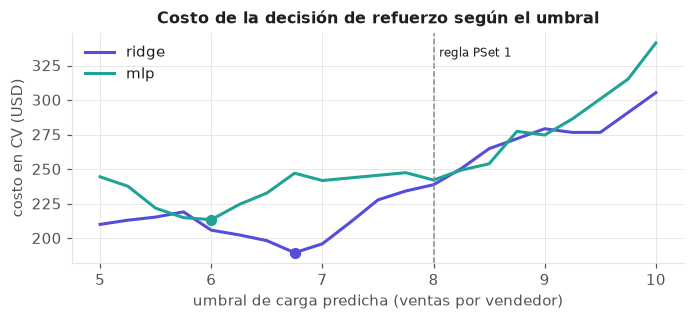

In [4]:
modelos = {n: mlflow.sklearn.load_model(f"runs:/{finalistas.loc[n, 'run_id']}/modelo") for n in (ganador, segundo)}
umbrales, oofs = {}, {}
for n, m in modelos.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        r = P.evaluar(clone(m), div.train, pliegues)          # reproduce la CV registrada
    assert np.isclose(r.metricas["cv_wape_mean"], finalistas.loc[n, "cv_wape_mean"]), "la CV no se reproduce"
    en_cv = ~np.isnan(r.oof)
    oofs[n] = (y_tr[en_cv], r.oof[en_cv], staff_tr[en_cv])
    umbrales[n] = P.umbral_optimo(*oofs[n])
    c8 = P.costo_negocio(*oofs[n])["costo"]
    cu = P.costo_negocio(*oofs[n], umbral=umbrales[n])["costo"]
    print(f"{n}: umbral óptimo {umbrales[n]:.2f} · costo en CV con 8: ${c8:.0f} → con el umbral óptimo: ${cu:.0f}")

grilla = np.arange(5.0, 10.01, 0.25)
fig, ax = plt.subplots(figsize=(6.4, 3))
for n, color in zip((ganador, segundo), (estilo.INDIGO, estilo.TEAL)):
    ax.plot(grilla, [P.costo_negocio(*oofs[n], umbral=u)["costo"] for u in grilla], color=color, label=n)
    ax.scatter([umbrales[n]], [P.costo_negocio(*oofs[n], umbral=umbrales[n])["costo"]], color=color, s=40, zorder=3)
ax.axvline(8, color=estilo.GRIS, lw=1, ls="--"); ax.text(8.05, ax.get_ylim()[1] * 0.95, "regla PSet 1", fontsize=8)
ax.set(xlabel="umbral de carga predicha (ventas por vendedor)", ylabel="costo en CV (USD)",
       title="Costo de la decisión de refuerzo según el umbral")
ax.legend(); fig.tight_layout(); estilo.guardar(fig, "seleccion_umbral"); plt.show()

## 4. Evaluación única en el conjunto de prueba

In [5]:
prueba = {}
for n, m in modelos.items():
    t0 = time.perf_counter()
    for _ in range(50):
        pred = m.predict(X_te)
    ms_inferencia = (time.perf_counter() - t0) / 50 * 1000
    neg = P.costo_negocio(y_te, pred, staff_te, umbral=umbrales[n])
    neg8 = P.costo_negocio(y_te, pred, staff_te)
    prueba[n] = {"test_wape": P.wape(y_te, pred), "test_mae": P.mae(y_te, pred),
                 "test_costo_negocio": neg["costo"], "test_costo_negocio_umbral8": neg8["costo"],
                 "test_horas_sobrecarga_detectadas": neg["tp"], "test_horas_sobrecarga_perdidas": neg["fn"],
                 "test_refuerzos_innecesarios": neg["fp"], "test_recall_sobrecarga": neg["recall_sobrecarga"],
                 "umbral_decision": umbrales[n], "inferencia_ms_139_filas": ms_inferencia,
                 "fit_seconds": finalistas.loc[n, "fit_seconds"], "pred": pred}

# Referencia (no participa en la selección): la regla de negocio del PSet 1 aplicada a las mismas semanas.
regla = P.ReglaPromedio4Semanas().fit(X_tr, y_tr).predict(X_te)
ref = P.costo_negocio(y_te, regla, staff_te)
tabla_prueba = pd.DataFrame({n: {k: v for k, v in d.items() if k != "pred"} for n, d in prueba.items()}).T
tabla_prueba.loc["regla PSet 1 (referencia)", ["test_wape", "test_mae", "test_costo_negocio", "test_costo_negocio_umbral8", "test_horas_sobrecarga_detectadas",
                                               "test_horas_sobrecarga_perdidas", "test_refuerzos_innecesarios", "test_recall_sobrecarga", "umbral_decision"]] = [
    P.wape(y_te, regla), P.mae(y_te, regla), ref["costo"], ref["costo"], ref["tp"], ref["fn"], ref["fp"], ref["recall_sobrecarga"], 8.0]
tabla_prueba.to_csv(RAIZ / "docs" / "resultados_prueba.csv")
tabla_prueba.astype(float).round(3)

,test_wape,test_mae,test_costo_negocio,test_costo_negocio_umbral8,test_horas_sobrecarga_detectadas,test_horas_sobrecarga_perdidas,test_refuerzos_innecesarios,test_recall_sobrecarga,umbral_decision,inferencia_ms_139_filas,fit_seconds
ridge,0.364,2.357,83.26,87.04,9.0,9.0,7.0,0.500,6.75,1.310,0.003
mlp,0.358,2.322,84.78,82.50,11.0,7.0,13.0,0.611,6.00,1.272,0.143
regla PSet 1 (referencia),0.394,2.555,75.31,75.31,9.0,9.0,4.0,0.500,8.00,NaN,NaN


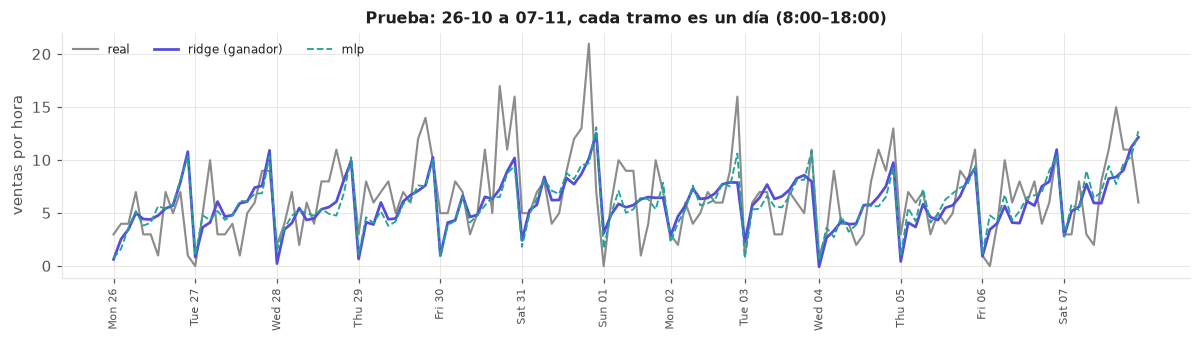

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.2))
x = np.arange(len(y_te))
ax.plot(x, y_te, color=estilo.GRIS, lw=1.4, label="real")
ax.plot(x, prueba[ganador]["pred"], color=estilo.INDIGO, lw=1.8, label=f"{ganador} (ganador)")
ax.plot(x, prueba[segundo]["pred"], color=estilo.TEAL, lw=1.2, ls="--", label=segundo)
cambios = np.flatnonzero(div.test.hour_date.diff().dt.days.fillna(1).to_numpy() > 0)
ax.set_xticks(cambios, [f"{d:%a %d}" for d in div.test.hour_date.iloc[cambios]], fontsize=7, rotation=90)
ax.set(ylabel="ventas por hora", title="Prueba: 26-10 a 07-11, cada tramo es un día (8:00–18:00)")
ax.legend(ncols=3, fontsize=8, loc="upper left"); fig.tight_layout(); estilo.guardar(fig, "seleccion_prueba"); plt.show()

## 5. Explicabilidad

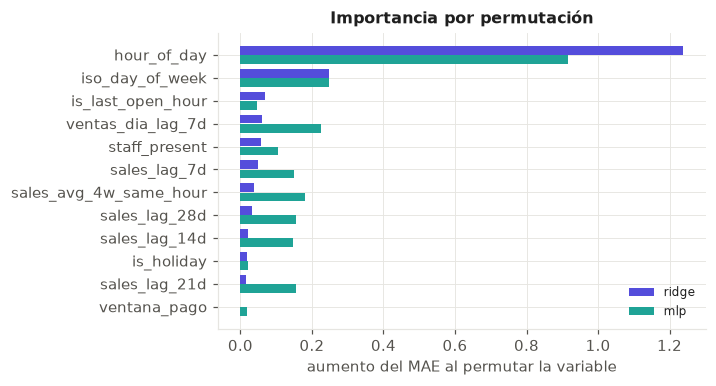

,ridge,mlp
hour_of_day,1.239,0.916
iso_day_of_week,0.249,0.249
is_last_open_hour,0.070,0.047
ventas_dia_lag_7d,0.059,0.227
staff_present,0.058,0.106
sales_lag_7d,0.050,0.149
sales_avg_4w_same_hour,0.039,0.182
sales_lag_28d,0.032,0.157
sales_lag_14d,0.022,0.147
is_holiday,0.020,0.020


In [7]:
imp = {}
for n, m in modelos.items():
    r = permutation_importance(m, X_tr, y_tr, scoring="neg_mean_absolute_error", n_repeats=10,
                               random_state=P.SEMILLA)
    imp[n] = pd.Series(r.importances_mean, index=P.ENTRADA)
imp = pd.DataFrame(imp).drop(index="hour_date").sort_values(ganador, ascending=True)
fig, ax = plt.subplots(figsize=(6.6, 3.6))
yy = np.arange(len(imp))
ax.barh(yy + 0.2, imp[ganador], height=0.38, color=estilo.INDIGO, label=ganador)
ax.barh(yy - 0.2, imp[segundo], height=0.38, color=estilo.TEAL, label=segundo)
ax.set_yticks(yy, imp.index); ax.set(xlabel="aumento del MAE al permutar la variable", title="Importancia por permutación")
ax.legend(fontsize=8); fig.tight_layout(); estilo.guardar(fig, "seleccion_importancia"); plt.show()
imp.sort_values(ganador, ascending=False).round(3)

In [8]:
# Si el ganador es lineal, su predicción se explica término a término.
est = modelos[ganador].named_steps["modelo"]
est = getattr(est, "regressor_", est)
if hasattr(est, "coef_"):
    nombres = modelos[ganador].named_steps["prep"].get_feature_names_out()
    coef = pd.Series(est.coef_, index=nombres).sort_values()
    display(pd.concat([coef.head(6), coef.tail(6)]).round(3).to_frame("coeficiente"))

,coeficiente
hour_of_day_8,-3.929
hour_of_day_9,-2.179
is_last_open_hour,-1.660
hour_of_day_10,-1.618
iso_day_of_week_3,-0.956
hour_of_day_13,-0.584
iso_day_of_week_7,0.391
hour_of_day_16,0.736
hour_of_day_17,1.899
is_holiday,1.913


## 6. Registro: corrida final y Model Registry

In [9]:
nombre_registro = T.MODELO_REGISTRADO
versiones = {}
for rol, n in (("champion", ganador), ("challenger", segundo)):
    origen = mlflow.get_run(finalistas.loc[n, "run_id"])
    m = modelos[n]
    with mlflow.start_run(run_name=f"final_{rol}_{n}") as run:
        mlflow.log_params({**{k: v for k, v in origen.data.params.items() if not k.startswith("datos_")},
                           "run_id_origen": origen.info.run_id, "version_elegida": finalistas.loc[n, "version"]})
        mlflow.log_params({k: v for k, v in origen.data.params.items() if k.startswith("datos_")})
        mlflow.log_metrics({k: v for k, v in origen.data.metrics.items() if k != "cv_wape_pliegue"})
        mlflow.log_metrics({k: float(v) for k, v in prueba[n].items() if k != "pred"})
        mlflow.set_tags({"fase": "final", "familia": origen.data.tags["familia"], "rol": rol,
                         "git_commit": T.commit_git()})
        firma = infer_signature(X_tr.head(5), m.predict(X_tr.head(5)).astype(float))
        info = mlflow.sklearn.log_model(m, name="modelo", signature=firma, input_example=X_tr.head(5),
                                        serialization_format="cloudpickle", code_paths=[str(RAIZ / "src")],
                                        registered_model_name=nombre_registro)
    v = info.registered_model_version
    cliente.set_registered_model_alias(nombre_registro, rol, v)
    cliente.set_model_version_tag(nombre_registro, v, "umbral_decision", f"{umbrales[n]:.2f}")
    versiones[rol] = (n, run.info.run_id, v)
    print(f"{rol:<10} {n:<14} run_id {run.info.run_id} · versión {v} · test WAPE {prueba[n]['test_wape']:.4f}")

2026/11/18 10:22:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/18 10:22:56 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Successfully registered model 'ventas-hora-matriz-modelo'.
2026/11/18 10:22:57 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ventas-hora-matriz-modelo, version 1


Created version '1' of model 'ventas-hora-matriz-modelo'.


champion   ridge          run_id b2a93515cf00415f9b32336eadbe00bf · versión 1 · test WAPE 0.3635


2026/11/18 10:22:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/18 10:23:00 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'ventas-hora-matriz-modelo' already exists. Creating a new version of this model...
2026/11/18 10:23:00 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ventas-hora-matriz-modelo, version 2


Created version '2' of model 'ventas-hora-matriz-modelo'.


challenger mlp            run_id 27188e892fc64cb9ace4bdf4d9719a8c · versión 2 · test WAPE 0.3582


## 7. Exportar todas las corridas del experimento

In [10]:
corridas = mlflow.search_runs(experiment_names=[T.EXPERIMENTO], max_results=10000)
cols = (["run_id", "tags.mlflow.runName", "tags.fase", "tags.familia", "tags.rol", "tags.git_commit",
         "tags.mlflow.parentRunId", "start_time", "end_time", "status"]
        + sorted(c for c in corridas.columns if c.startswith("metrics."))
        + sorted(c for c in corridas.columns if c.startswith("params.")))
corridas = corridas[[c for c in cols if c in corridas.columns]].sort_values("start_time")
corridas.to_csv(RAIZ / "docs" / "corridas.csv", index=False)
print(f"{len(corridas)} corridas exportadas a docs/corridas.csv")
corridas["tags.fase"].value_counts()

104 corridas exportadas a docs/corridas.csv


tags.fase
tuning       93
candidato     7
baseline      2
final         2
Name: count, dtype: int64

## Decisión

**Champion: Ridge (hiperparámetros por defecto).**

- **Frente a la MLP (challenger)**, la diferencia en CV es de 0,013, muy por debajo de la desviación entre pliegues (0,043). Pareado por semana, Ridge gana en 4 de 5 pliegues, con una diferencia de 0,013 ± 0,016. En la prueba la MLP queda levemente por delante (0,358 contra 0,364): el orden se invierte dentro del ruido, lo que confirma que **los dos son equivalentes en precisión**.
- **Ridge gana por parsimonia**: entrena unas 50 veces más rápido (3 ms frente a 143 ms), predice la semana en ~1 ms, tiene menor costo de negocio en la CV con su umbral calibrado ($190 contra $213) y **se puede explicar término a término**. Por ejemplo, la hora de las 18:00 suma unas 6 ventas frente a la media, el sábado unas 2, un feriado unas 2, y la última hora abierta resta 1,7.

**Métrica técnica en la prueba:** WAPE 0,364, frente a 0,394 de la regla del PSet 1 (3 puntos mejor, en línea con la CV).

**Métrica de negocio en la prueba:** el umbral calibrado con predicciones fuera de pliegue es 6,75 ventas por vendedor (no 8). Con él, Ridge cuesta **$83** en las dos semanas de prueba, frente a **$75** de la regla. Los dos detectan 9 de las 18 horas sobrecargadas, pero Ridge genera más refuerzos innecesarios (7 contra 4). **Hallazgo:** un mejor WAPE no se tradujo en una mejor decisión de refuerzo. El WAPE premia acertar en todas las horas, mientras que la decisión depende solo de acertar en los picos, donde un modelo de media los aplana. Con dos semanas y 18 horas sobrecargadas, esta diferencia de costo tampoco es concluyente. El paso siguiente (PSet 4) es optimizar la decisión directamente: un pronóstico por cuantiles, o un clasificador de sobrecarga.